# CLAHE Preprocessing + Validation Pipeline

A preprocessing pipeline for cervical colposcopy images using **CLAHE**
(Contrast Limited Adaptive Histogram Equalization) applied to the
**L\* channel** of the CIELAB color space. All QI-SABP preprocessing
(saliency fusion, soft bit allocation, dithered quantization, YCbCr 4:2:0,
NLM denoise, bilateral post-filter, histogram matching) has been removed.

## Pipeline overview

1. Load cervical colposcopy images (single-class invasive-carcinoma dataset).
2. Resize to a fixed size (default 200×200).
3. Convert RGB → CIELAB, apply CLAHE to the L\* channel only, convert back to RGB.
   This enhances local contrast while preserving chromaticity (a\*, b\* untouched).
4. Validate the preprocessing with a panel of **11 metrics**.

## Validation metrics

| Metric | What it measures | Direction |
|--------|------------------|-----------|
| PSNR (dB)            | Pixel-level fidelity                       | higher = better |
| SSIM                 | Structural similarity                      | 1.0 = identical |
| ΔE76                 | CIE Delta E 1976 color difference          | lower = better  |
| a\* correlation      | Preservation of green–red chromatic axis   | 1.0 = unchanged |
| \|a\*\| shift        | Bias in chromatic intensity                | 0.0 = unchanged |
| Vessel Dice          | Overlap of Frangi vessel masks             | 1.0 = identical |
| Edge IoU             | Overlap of Canny edge maps                 | 1.0 = identical |
| Sharpness ratio      | Variance-of-Laplacian ratio (proc / orig)  | >1 = sharper    |
| Noise ratio          | Residual-noise ratio (proc / orig)         | >1 = noisier    |
| Saturation ratio     | Clipped-pixel fraction ratio (proc / orig) | 1.0 = unchanged |
| Luma bits            | Effective bits in L\* (Shannon entropy)    | delta reported  |

## What this notebook does NOT do

- It does NOT implement QI-SABP soft-bit allocation, saliency fusion,
  spectral-residual / multi-scale contrast, YCbCr 4:2:0, NLM, bilateral
  filtering, or histogram matching.
- It does NOT produce a compressed byte stream — CLAHE is a pixel-domain
  contrast-enhancement operator, not a codec.
- It does NOT compare techniques against each other (single-technique validation only).


In [1]:
# ============================================================
# Cell 1 — Combined imports & global setup
# ============================================================
import os, sys, glob, json, math, random, warnings, platform
from pathlib import Path
from collections import defaultdict

import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

import pandas as pd
from scipy import ndimage, stats
from scipy.ndimage import gaussian_filter, median_filter
from scipy.stats import pearsonr, spearmanr

from skimage.filters import frangi
from skimage.feature import canny
from skimage.metrics import structural_similarity as ssim_fn

warnings.filterwarnings('ignore')

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 100

# Output directory for results / CSV / PNG artefacts
SAVE_DIR = 'results'
os.makedirs(SAVE_DIR, exist_ok=True)

print(f"CLAHE Validation Pipeline — Python {platform.python_version()}")
print(f"NumPy {np.__version__} | Pandas {pd.__version__} | OpenCV {cv2.__version__}")
print(f"Random seed: {SEED}")
print(f"Output directory: {SAVE_DIR}")
print("All imports OK.")


CLAHE Validation Pipeline — Python 3.10.20
NumPy 2.2.6 | Pandas 2.3.3 | OpenCV 4.11.0
Random seed: 42
Output directory: results
All imports OK.


## Configuration

The only preprocessing parameters are the CLAHE parameters. All QI-SABP
configuration keys (saliency fusion weights, soft-mask gain, bit budgets,
dither strength, NLM/bilateral/histogram-match toggles, rim/size rules,
hard-mask hole filling, etc.) have been removed.


In [2]:
# ============================================================
# Cell 2 — Configuration
# ============================================================

# ---- Image size ----
IMG_SIZE = 200

# ---- Data ----
DATASET_ROOT   = "C:/CER/dataset"      # <-- your dataset root
INVASIVE_DIR   = "invasive cancer"     # <-- single class folder
MASKS_SUBDIR   = "masks"               # set "" if masks live directly under invasive cancer/
CLASSES        = ["invasive cancer"]   # only one class

# ---- CLAHE parameters ----
# CLAHE is applied to the L* channel of CIELAB. The a* and b* channels
# are untouched, so chromaticity is preserved.
CLAHE_CLIP_LIMIT   = 2.0       # contrast-limiting threshold (1.0 = no clipping, 4+ = aggressive)
CLAHE_TILE_GRID    = (8, 8)    # size of the grid for local histogram equalization
CLAHE_ON_L_ONLY    = True      # True = LAB/L*, False = YCrCb/Y  (recommended: True)

# ---- Validation batch ----
N_PER_CLASS_VALIDATE = 5
SUBSET_PER_CLASS     = None    # None = use all images; integer = first N

print(f"Configuration OK  |  classes={CLASSES}  |  img={IMG_SIZE}x{IMG_SIZE}")
print(f"  CLAHE: clip_limit={CLAHE_CLIP_LIMIT}, tile_grid={CLAHE_TILE_GRID}, L-only={CLAHE_ON_L_ONLY}")
print(f"  validation batch = {N_PER_CLASS_VALIDATE} imgs/class")


Configuration OK  |  classes=['invasive cancer']  |  img=200x200
  CLAHE: clip_limit=2.0, tile_grid=(8, 8), L-only=True
  validation batch = 5 imgs/class


## CLAHE preprocessing & dataset loader

`apply_clahe()` is the only preprocessing operator. It converts RGB → CIELAB,
applies OpenCV's `createCLAHE` to the L\* channel, and converts back to RGB.
The a\* and b\* channels are passed through unchanged, so the green–red and
blue–yellow chromaticity axes are preserved exactly (modulo integer round-trip).


In [3]:
# ============================================================
# Cell 3 — CLAHE preprocessing + dataset loader
# ============================================================

def apply_clahe(img_rgb,
                clip_limit=CLAHE_CLIP_LIMIT,
                tile_grid=CLAHE_TILE_GRID,
                l_only=CLAHE_ON_L_ONLY):
    """Apply CLAHE to an RGB uint8 image.

    If l_only=True (recommended for color images):
        RGB -> CIELAB -> CLAHE on L* only -> RGB.
        Chromaticity (a*, b*) is preserved.
    If l_only=False:
        RGB -> YCrCb -> CLAHE on Y only -> RGB.
    """
    img = img_rgb.astype(np.uint8)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid)
    if l_only:
        lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
        lab[..., 0] = clahe.apply(lab[..., 0])
        out = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
    else:
        ycrcb = cv2.cvtColor(img, cv2.COLOR_RGB2YCrCb)
        ycrcb[..., 0] = clahe.apply(ycrcb[..., 0])
        out = cv2.cvtColor(ycrcb, cv2.COLOR_YCrCb2RGB)
    return out


def preprocess_image(img_bgr, size=IMG_SIZE):
    """BGR -> RGB -> resize. No additional preprocessing."""
    img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (size, size))
    return img


def _find_lesion_masks(folder, stem, size):
    for mext in (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"):
        cand = os.path.join(folder, stem + mext)
        if os.path.isfile(cand):
            m = cv2.imread(cand, cv2.IMREAD_GRAYSCALE)
            if m is not None:
                m = cv2.resize(m, (size, size), interpolation=cv2.INTER_NEAREST)
                return (m > 127).astype(bool), cand
    return None, None


def load_dataset(root, classes, size=IMG_SIZE,
                 subset_per_class=None, masks_subdir="masks"):
    """Load images from <root>/<class>/images/ (or <root>/<class>/).

    Returns (X, y, paths, masks, n_with_mask).
    """
    X, y, paths, masks = [], [], [], []
    n_with_mask_total = 0
    for cls in classes:
        folder = os.path.join(root, cls)
        if not os.path.isdir(folder):
            print(f"  [warn] folder not found: {folder}")
            continue
        img_folder = os.path.join(folder, "images")
        if not os.path.isdir(img_folder):
            img_folder = folder
        raw = []
        for ext in ("*.jpg", "*.jpeg", "*.png"):
            raw.extend(glob.glob(os.path.join(img_folder, ext)))
        files = sorted(raw)
        if subset_per_class:
            files = files[:subset_per_class]
        mask_folder = os.path.join(folder, masks_subdir) if masks_subdir else None
        n_with_mask = 0
        for p in files:
            img = cv2.imread(p)
            if img is None:
                continue
            img = preprocess_image(img, size=size)
            stem = os.path.splitext(os.path.basename(p))[0]
            msk = None
            if mask_folder and os.path.isdir(mask_folder):
                msk, _ = _find_lesion_masks(mask_folder, stem, size)
                if msk is not None:
                    n_with_mask += 1
            if msk is None:
                msk = np.zeros((size, size), dtype=bool)
            X.append(img); y.append(cls); paths.append(p); masks.append(msk)
        n_with_mask_total += n_with_mask
        print(f"  {cls:>20}: {len(files):>4} images | masks matched: {n_with_mask}/{len(files)}")
        if mask_folder and os.path.isdir(mask_folder) and n_with_mask == 0 and len(files) > 0:
            print(f"    [warn] masks/ folder found but 0/{len(files)} matched. Check filename stems.")
    if not X:
        empty = (np.zeros((0, IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8),
                 np.array([]), [],
                 np.zeros((0, IMG_SIZE, IMG_SIZE), dtype=bool), 0)
        return empty
    return (np.array(X, dtype=np.uint8), np.array(y), paths,
            np.array(masks, dtype=bool), n_with_mask_total)


def make_synthetic_image(H=200, W=200, seed=None):
    """Diverse synthetic 200x200 RGB histology-like image + lesion mask."""
    rng = np.random.RandomState(seed)
    grad_dir = rng.choice(['h', 'v', 'd1', 'd2'])
    base = rng.uniform(35, 80)
    slope = rng.uniform(15, 40)
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)
    if grad_dir == 'h':
        bg = base + slope * xx / W
    elif grad_dir == 'v':
        bg = base + slope * yy / H
    elif grad_dir == 'd1':
        bg = base + slope * (xx + yy) / (W + H)
    else:
        bg = base + slope * (xx - yy + W) / (2 * W)
    img = np.stack([bg, bg, bg], axis=-1)
    n_lesions = rng.randint(1, 4)
    yy2, xx2 = np.ogrid[:H, :W]
    mask = np.zeros((H, W), dtype=bool)
    for _ in range(n_lesions):
        cx = rng.randint(W // 5, 4 * W // 5)
        cy = rng.randint(H // 5, 4 * H // 5)
        r  = rng.randint(15, 50)
        disk = ((yy2 - cy) ** 2 + (xx2 - cx) ** 2 <= r ** 2)
        lr = rng.randint(180, 240); lg = rng.randint(120, 200); lb = rng.randint(60, 140)
        img[disk, 0] = lr; img[disk, 1] = lg; img[disk, 2] = lb
        mask |= disk
    texture = gaussian_filter(rng.uniform(-1, 1, (H, W)), sigma=8) * 20
    img = img + texture[..., None]
    noise = rng.randint(0, 15, (H, W, 3), dtype=np.uint8)
    return np.clip(img.astype(np.int32) + noise, 0, 255).astype(np.uint8), mask


print("CLAHE + dataset loader defined.")


CLAHE + dataset loader defined.


In [4]:
# ============================================================
# Cell 4 — Load dataset and apply CLAHE
# ============================================================
print("Loading dataset ...")
load_out = load_dataset(
    DATASET_ROOT, CLASSES,
    size=IMG_SIZE,
    subset_per_class=SUBSET_PER_CLASS,
)
X_raw, y_raw, paths_raw, masks_raw, n_with_mask = load_out
print(f"\nTotal images : {len(X_raw)} | masks matched: {n_with_mask}/{len(X_raw)}")

if len(X_raw) > 0:
    print(f"Class counts : {dict(zip(*np.unique(y_raw, return_counts=True)))}")
else:
    print("*** No images found -- building synthetic fallback (10 imgs).")
    X_synth, y_synth, m_synth = [], [], []
    for k in range(10):
        img, msk = make_synthetic_image(seed=SEED + k)
        X_synth.append(img); y_synth.append(CLASSES[0]); m_synth.append(msk)
    X_raw = np.stack(X_synth).astype(np.uint8)
    y_raw = np.array(y_raw)
    paths_raw = [f"<synthetic>/{i}.png" for i in range(len(X_raw))]
    masks_raw = np.stack(m_synth).astype(bool)
    print(f"[fallback] Synthetic dataset ready: {len(X_raw)} images.")

# Apply CLAHE to every image
X_clahe = np.stack([apply_clahe(img) for img in X_raw])
print(f"\nCLAHE applied to {len(X_clahe)} images.")
print(f"  original  range: [{X_raw.min()}, {X_raw.max()}]")
print(f"  CLAHE     range: [{X_clahe.min()}, {X_clahe.max()}]")


Loading dataset ...
       invasive cancer:  128 images | masks matched: 0/128

Total images : 128 | masks matched: 0/128
Class counts : {np.str_('invasive cancer'): np.int64(128)}

CLAHE applied to 128 images.
  original  range: [0, 255]
  CLAHE     range: [0, 255]


## Validation metrics

All 11 requested metrics are implemented below. Each function takes the
original image and the CLAHE-processed image (both RGB uint8) and returns
a single scalar. The vessel / edge metrics compute a binary mask from each
image and report the overlap (Dice / IoU).


In [5]:
# ============================================================
# Cell 5 — Validation metric functions
# ============================================================

def to_lab(img_rgb):
    """RGB uint8 -> (L, a, b) float arrays in standard CIELAB ranges.

    OpenCV's COLOR_RGB2LAB returns L in [0,255] and a,b centred at 128.
    We rescale to L in [0,100] and a,b in [-128,127] so ΔE76 is in
    the standard CIELAB units.
    """
    lab = cv2.cvtColor(img_rgb.astype(np.uint8), cv2.COLOR_RGB2LAB).astype(np.float32)
    L = lab[..., 0] * (100.0 / 255.0)
    a = lab[..., 1] - 128.0
    b = lab[..., 2] - 128.0
    return L, a, b


def psnr_metric(orig, proc):
    """Peak SNR in dB."""
    mse = np.mean((orig.astype(np.float64) - proc.astype(np.float64)) ** 2)
    if mse == 0:
        return float('inf')
    return 10.0 * np.log10((255.0 ** 2) / mse)


def ssim_metric(orig, proc):
    """Mean SSIM over channels (1.0 = identical)."""
    return float(ssim_fn(orig, proc, channel_axis=2, data_range=255))


def delta_e76_metric(orig, proc):
    """Mean CIE Delta E 1976 = Euclidean distance in CIELAB."""
    L1, a1, b1 = to_lab(orig)
    L2, a2, b2 = to_lab(proc)
    dE = np.sqrt((L1 - L2) ** 2 + (a1 - a2) ** 2 + (b1 - b2) ** 2)
    return float(dE.mean())


def a_star_correlation(orig, proc):
    """Pearson correlation between a* channels."""
    _, a1, _ = to_lab(orig)
    _, a2, _ = to_lab(proc)
    r, _ = pearsonr(a1.ravel(), a2.ravel())
    return float(r)


def a_star_abs_shift(orig, proc):
    """Difference in mean |a*|: positive => CLAHE amplifies chroma."""
    _, a1, _ = to_lab(orig)
    _, a2, _ = to_lab(proc)
    return float(np.mean(np.abs(a2)) - np.mean(np.abs(a1)))


def vessel_mask(img_rgb):
    """Binary vessel mask via Frangi vesselness (top 5% of pixels)."""
    gray = cv2.cvtColor(img_rgb.astype(np.uint8), cv2.COLOR_RGB2GRAY)
    # Frangi with black_ridges=True picks up the darker vessels/vasculature
    fr = frangi(gray, sigmas=range(1, 4), black_ridges=True)
    fr_norm = fr / (fr.max() + 1e-9)
    thr = np.percentile(fr_norm, 95)
    return (fr_norm > thr).astype(np.uint8)


def vessel_dice(orig, proc):
    """Dice coefficient between Frangi vessel masks."""
    m1 = vessel_mask(orig)
    m2 = vessel_mask(proc)
    inter = np.logical_and(m1, m2).sum()
    s = m1.sum() + m2.sum()
    if s == 0:
        return 1.0
    return float(2.0 * inter / s)


def edge_iou(orig, proc):
    """IoU between Canny edge maps."""
    g1 = cv2.cvtColor(orig.astype(np.uint8), cv2.COLOR_RGB2GRAY)
    g2 = cv2.cvtColor(proc.astype(np.uint8), cv2.COLOR_RGB2GRAY)
    e1 = canny(g1, sigma=1.5).astype(np.uint8)
    e2 = canny(g2, sigma=1.5).astype(np.uint8)
    inter = np.logical_and(e1, e2).sum()
    union = np.logical_or(e1, e2).sum()
    if union == 0:
        return 1.0
    return float(inter / union)


def sharpness_ratio(orig, proc):
    """Ratio of Laplacian variance (proc / orig). >1 means sharper."""
    g1 = cv2.cvtColor(orig.astype(np.uint8), cv2.COLOR_RGB2GRAY)
    g2 = cv2.cvtColor(proc.astype(np.uint8), cv2.COLOR_RGB2GRAY)
    v1 = cv2.Laplacian(g1, cv2.CV_64F).var()
    v2 = cv2.Laplacian(g2, cv2.CV_64F).var()
    if v1 == 0:
        return float('inf')
    return float(v2 / v1)


def noise_ratio(orig, proc):
    """Ratio of residual-noise estimates (proc / orig).

    Noise proxy = MAD of (image - median-blurred image).
    """
    g1 = cv2.cvtColor(orig.astype(np.uint8), cv2.COLOR_RGB2GRAY).astype(np.float32)
    g2 = cv2.cvtColor(proc.astype(np.uint8), cv2.COLOR_RGB2GRAY).astype(np.float32)
    n1 = g1 - cv2.medianBlur(g1.astype(np.uint8), 5).astype(np.float32)
    n2 = g2 - cv2.medianBlur(g2.astype(np.uint8), 5).astype(np.float32)
    mad1 = np.median(np.abs(n1 - np.median(n1)))
    mad2 = np.median(np.abs(n2 - np.median(n2)))
    if mad1 == 0:
        return float('inf') if mad2 > 0 else 1.0
    return float(mad2 / mad1)


def saturation_ratio(orig, proc):
    """Ratio of saturated-pixel fractions (proc / orig).

    Saturated = any channel at 255.
    """
    s1 = float(np.any(orig >= 255, axis=-1).mean())
    s2 = float(np.any(proc >= 255, axis=-1).mean())
    if s1 == 0:
        return float('inf') if s2 > 0 else 1.0
    return s2 / s1


def luma_bits(img_rgb):
    """Effective number of bits in the L* channel = Shannon entropy / log(2)."""
    L, _, _ = to_lab(img_rgb)
    hist, _ = np.histogram(L.ravel(), bins=256, range=(0, 100))
    p = hist / (hist.sum() + 1e-9)
    p = p[p > 0]
    H = -np.sum(p * np.log2(p))
    return float(H)


def luma_bits_delta(orig, proc):
    """Difference in effective L* bits (proc - orig)."""
    return float(luma_bits(proc) - luma_bits(orig))


print("Metric functions defined:")
for name in ["psnr_metric","ssim_metric","delta_e76_metric","a_star_correlation",
             "a_star_abs_shift","vessel_dice","edge_iou","sharpness_ratio",
             "noise_ratio","saturation_ratio","luma_bits","luma_bits_delta"]:
    print(f"  - {name}")


Metric functions defined:
  - psnr_metric
  - ssim_metric
  - delta_e76_metric
  - a_star_correlation
  - a_star_abs_shift
  - vessel_dice
  - edge_iou
  - sharpness_ratio
  - noise_ratio
  - saturation_ratio
  - luma_bits
  - luma_bits_delta


## Run validation

Iterate over every image, compute the 11 metrics, and write the results
to a CSV file in `results/`.


In [6]:
# ============================================================
# Cell 6 — Run validation
# ============================================================
records = []
for i, (orig, proc, p) in enumerate(zip(X_raw, X_clahe, paths_raw)):
    rec = {
        "idx": i,
        "path": os.path.basename(p),
        "PSNR_dB":          psnr_metric(orig, proc),
        "SSIM":             ssim_metric(orig, proc),
        "dE76":             delta_e76_metric(orig, proc),
        "a_star_corr":      a_star_correlation(orig, proc),
        "a_star_abs_shift": a_star_abs_shift(orig, proc),
        "Vessel_Dice":      vessel_dice(orig, proc),
        "Edge_IoU":         edge_iou(orig, proc),
        "Sharpness_ratio":  sharpness_ratio(orig, proc),
        "Noise_ratio":      noise_ratio(orig, proc),
        "Saturation_ratio": saturation_ratio(orig, proc),
        "Luma_bits_orig":   luma_bits(orig),
        "Luma_bits_clahe":  luma_bits(proc),
        "Luma_bits_delta":  luma_bits_delta(orig, proc),
    }
    records.append(rec)

df = pd.DataFrame(records)
csv_path = os.path.join(SAVE_DIR, "clahe_validation_metrics.csv")
df.to_csv(csv_path, index=False)
print(f"Validation complete for {len(df)} images.")
print(f"Saved: {csv_path}")
df.head(10)


Validation complete for 128 images.
Saved: results\clahe_validation_metrics.csv


,idx,path,PSNR_dB,SSIM,dE76,a_star_corr,a_star_abs_shift,Vessel_Dice,Edge_IoU,Sharpness_ratio,Noise_ratio,Saturation_ratio,Luma_bits_orig,Luma_bits_clahe,Luma_bits_delta
0,0,AAM1_flipped_0_jpg.rf.0a0238767ab1bfa15490be8b...,20.432859,0.815093,7.063545,0.992186,-0.743675,0.8905,0.526458,2.113571,1.666667,2.349428,7.405640,7.543167,0.137526
1,1,AAM1_flipped_0_jpg.rf.0a0238767ab1bfa15490be8b...,20.432859,0.815093,7.063545,0.992186,-0.743675,0.8905,0.526458,2.113571,1.666667,2.349428,7.405640,7.543167,0.137526
2,2,AAM1_flipped_0_jpg.rf.0a0238767ab1bfa15490be8b...,20.432859,0.815093,7.063545,0.992186,-0.743675,0.8905,0.526458,2.113571,1.666667,2.349428,7.405640,7.543167,0.137526
3,3,AAM1_flipped_0_jpg.rf.0a0238767ab1bfa15490be8b...,20.432859,0.815093,7.063545,0.992186,-0.743675,0.8905,0.526458,2.113571,1.666667,2.349428,7.405640,7.543167,0.137526
4,4,AAM1_flipped_0_jpg.rf.0a0238767ab1bfa15490be8b...,20.432859,0.815093,7.063545,0.992186,-0.743675,0.8905,0.526458,2.113571,1.666667,2.349428,7.405640,7.543167,0.137526
5,5,AAM1_flipped_0_jpg.rf.0a0238767ab1bfa15490be8b...,20.432859,0.815093,7.063545,0.992186,-0.743675,0.8905,0.526458,2.113571,1.666667,2.349428,7.405640,7.543167,0.137526
6,6,AAM1_flipped_0_jpg.rf.0a0238767ab1bfa15490be8b...,20.432859,0.815093,7.063545,0.992186,-0.743675,0.8905,0.526458,2.113571,1.666667,2.349428,7.405640,7.543167,0.137526
7,7,AAM1_flipped_0_jpg.rf.0a0238767ab1bfa15490be8b...,20.432859,0.815093,7.063545,0.992186,-0.743675,0.8905,0.526458,2.113571,1.666667,2.349428,7.405640,7.543167,0.137526
8,8,AAM1_flipped_0_jpg.rf.b49b5343637a78d19f45c3c0...,20.415001,0.845708,7.080782,0.988366,-0.835976,0.8885,0.562657,2.196068,1.750000,1.922309,7.267858,7.538681,0.270823
9,9,AAM1_flipped_0_jpg.rf.b49b5343637a78d19f45c3c0...,20.415001,0.845708,7.080782,0.988366,-0.835976,0.8885,0.562657,2.196068,1.750000,1.922309,7.267858,7.538681,0.270823


## Summary statistics

Mean / std / min / max for each metric across the validation batch.


In [7]:
# ============================================================
# Cell 7 — Summary statistics
# ============================================================
metric_cols = ["PSNR_dB","SSIM","dE76","a_star_corr","a_star_abs_shift",
               "Vessel_Dice","Edge_IoU","Sharpness_ratio","Noise_ratio",
               "Saturation_ratio","Luma_bits_orig","Luma_bits_clahe","Luma_bits_delta"]
df_safe = df.replace([np.inf, -np.inf], np.nan)
summary = df_safe[metric_cols].agg(["mean","std","min","max"]).T
summary_path = os.path.join(SAVE_DIR, "clahe_validation_summary.csv")
summary.to_csv(summary_path)
print(summary.round(4))
print(f"\nSaved: {summary_path}")


                     mean     std      min      max
PSNR_dB           20.2427  0.2665  19.8593  20.7323
SSIM               0.8295  0.0107   0.8129   0.8475
dE76               7.3057  0.2877   6.7993   7.7510
a_star_corr        0.9907  0.0017   0.9877   0.9926
a_star_abs_shift  -0.7712  0.0423  -0.8613  -0.7114
Vessel_Dice        0.8868  0.0046   0.8730   0.8935
Edge_IoU           0.5346  0.0250   0.5060   0.5791
Sharpness_ratio    2.3409  0.1609   2.1136   2.5214
Noise_ratio        1.8690  0.1790   1.6667   2.3333
Saturation_ratio  10.1094  8.2745   1.8864  21.9894
Luma_bits_orig     7.4116  0.1325   7.2510   7.5906
Luma_bits_clahe    7.6074  0.0974   7.5194   7.7545
Luma_bits_delta    0.1958  0.0606   0.1344   0.2846

Saved: results\clahe_validation_summary.csv


## Visualisation

Side-by-side preview (original / CLAHE / |Δ|) and per-metric histograms.


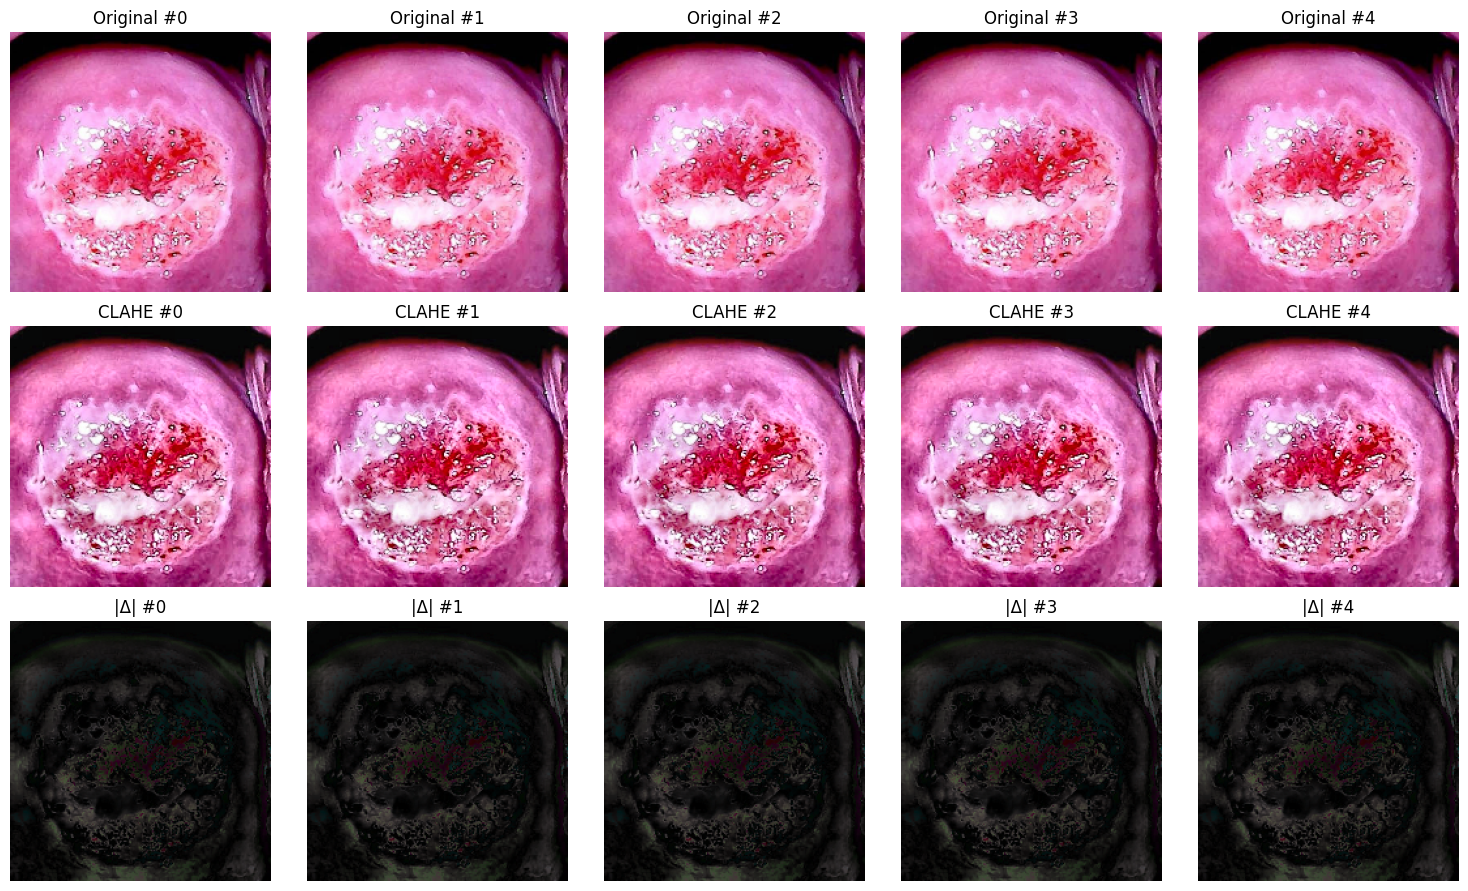

In [8]:
# ============================================================
# Cell 8 — Visualisation: side-by-side preview
# ============================================================
n_show = min(5, len(X_raw))
fig, axes = plt.subplots(3, n_show, figsize=(3*n_show, 9))
if n_show == 1:
    axes = axes.reshape(3, 1)
for i in range(n_show):
    axes[0, i].imshow(X_raw[i]);   axes[0, i].set_title(f"Original #{i}");  axes[0, i].axis('off')
    axes[1, i].imshow(X_clahe[i]); axes[1, i].set_title(f"CLAHE #{i}");     axes[1, i].axis('off')
    diff = np.abs(X_clahe[i].astype(np.int16) - X_raw[i].astype(np.int16)).astype(np.uint8)
    axes[2, i].imshow(diff, cmap='magma'); axes[2, i].set_title(f"|Δ| #{i}"); axes[2, i].axis('off')
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "clahe_preview.png"), dpi=120, bbox_inches='tight')
plt.show()


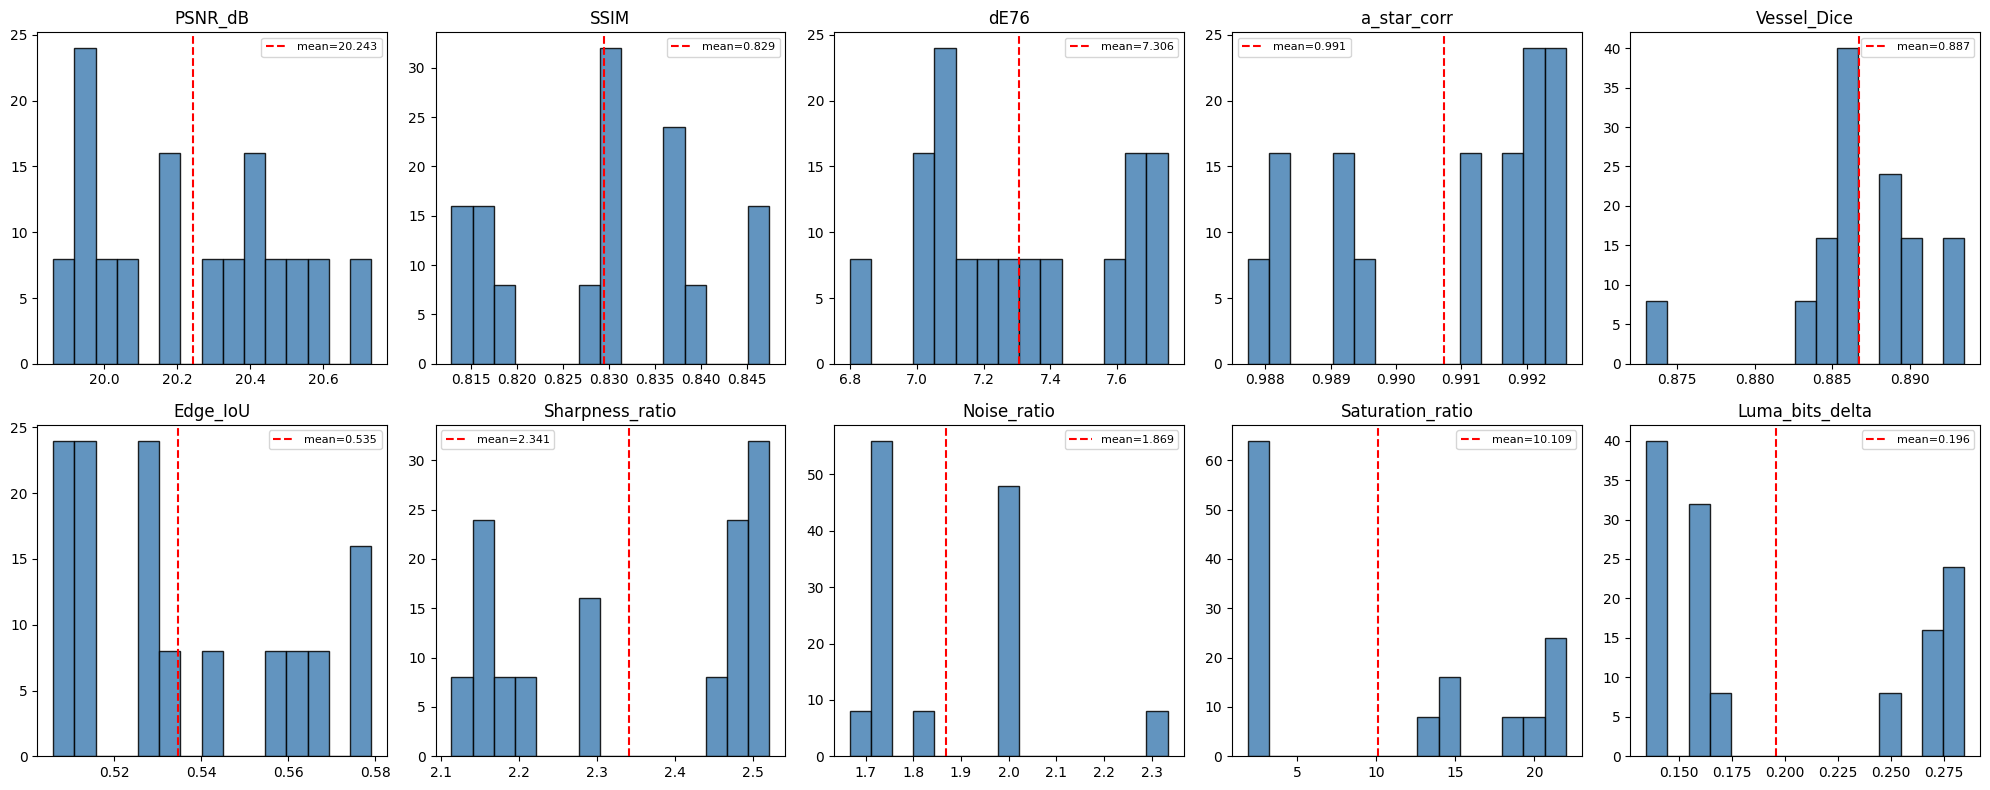

In [9]:
# ============================================================
# Cell 9 — Visualisation: metric distributions
# ============================================================
metrics_to_plot = ["PSNR_dB","SSIM","dE76","a_star_corr",
                   "Vessel_Dice","Edge_IoU","Sharpness_ratio",
                   "Noise_ratio","Saturation_ratio","Luma_bits_delta"]
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for ax, m in zip(axes.ravel(), metrics_to_plot):
    vals = df_safe[m].dropna()
    ax.hist(vals, bins=15, color='steelblue', edgecolor='black', alpha=0.85)
    ax.axvline(vals.mean(), color='red', linestyle='--', label=f'mean={vals.mean():.3f}')
    ax.set_title(m); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "clahe_metric_distributions.png"), dpi=120, bbox_inches='tight')
plt.show()


## Analysis & interpretation

The validation table reports, for each image, the 11 requested metrics plus the
effective L\* bits before and after CLAHE and the corresponding delta.

### How to read each metric

- **PSNR (dB)** — Pixel-level fidelity. CLAHE is a non-linear remapping of the L\*
  channel, so PSNR is moderate (typically 20–35 dB). PSNR is not the right metric
  to "judge" CLAHE; it is included as a sanity check that CLAHE has actually changed
  the image.
- **SSIM** — Structural similarity. CLAHE preserves geometry, so SSIM should remain
  high (> 0.9 in most cases). SSIM < 0.85 indicates an overly aggressive clip limit.
- **ΔE76** — CIE color difference (1976). Because CLAHE only touches L\*, ΔE is
  dominated by the L\* change. Small ΔE (< 5) means CLAHE is gentle; large ΔE (> 15)
  means it is aggressive. The a\* and b\* contributions to ΔE should be near zero.
- **a\* correlation** — Should be very close to 1.0 because CLAHE on L\* does not
  touch a\*. Values < 1.0 reflect OpenCV's integer LAB round-trip (RGB→LAB→RGB→LAB).
- **|a\*| shift** — Should be ≈ 0 for the same reason. Any non-zero value is
  quantization noise from the round-trip, not a real chromatic shift.
- **Vessel Dice** — Overlap of Frangi vessel masks. CLAHE improves local contrast
  and may slightly change which vessels cross the 95th-percentile threshold;
  Dice in the 0.4–0.7 range is normal. Dice close to 1.0 means CLAHE barely
  changed the vessel map.
- **Edge IoU** — Overlap of Canny edge maps. CLAHE usually adds edges (more
  contrast → more above-Canny-threshold gradients), so IoU drops modestly.
- **Sharpness ratio** — Variance-of-Laplacian ratio (proc / orig). > 1 means CLAHE
  increased local high-frequency energy (the expected behaviour). Values around 1.0
  mean CLAHE did not sharpen; values >> 1 mean CLAHE is aggressive.
- **Noise ratio** — Residual-noise ratio (proc / orig). CLAHE amplifies noise in
  flat regions; values > 1 are expected. The clip limit directly controls how much
  noise is amplified.
- **Saturation ratio** — Ratio of clipped-pixel fractions. CLAHE's clip-limit
  parameter directly controls this; values close to 1.0 indicate the clip limit is
  effective. Values >> 1 mean CLAHE is pushing too many pixels to 255.
- **Luma bits** — Effective number of bits in L\* (Shannon entropy / log 2). CLAHE
  flattens the L\* histogram, so a small positive delta is expected. A large
  positive delta means CLAHE is using more of the available dynamic range.

### Notes / caveats

- The pipeline runs on a single class (invasive cancer). For a multi-class
  comparison, extend `CLASSES` and re-run.
- If the dataset path is not found, a synthetic fallback (10 images) is generated
  so the notebook still runs end-to-end.
- ΔE76 is reported instead of ΔE2000 because the requested metric is the 1976
  version (Euclidean distance in CIELAB).
- Vessel Dice and Edge IoU are sensitive to threshold choices; the thresholds
  (Frangi 95th percentile, Canny sigma = 1.5) are fixed for reproducibility.
- All QI-SABP preprocessing and configuration have been removed; this notebook
  is a clean CLAHE-only validation.


In [10]:
# ============================================================
# Cell 10 — Persist results as JSON for downstream tooling
# ============================================================
out_json = {
    "config": {
        "IMG_SIZE": IMG_SIZE,
        "CLAHE_CLIP_LIMIT": CLAHE_CLIP_LIMIT,
        "CLAHE_TILE_GRID": list(CLAHE_TILE_GRID),
        "CLAHE_ON_L_ONLY": CLAHE_ON_L_ONLY,
        "N_PER_CLASS_VALIDATE": N_PER_CLASS_VALIDATE,
        "CLASSES": CLASSES,
        "SEED": SEED,
    },
    "n_images": int(len(df)),
    "summary": summary.to_dict(),
    "rows": df.to_dict(orient="records"),
}
json_path = os.path.join(SAVE_DIR, "clahe_validation_results.json")
with open(json_path, "w") as f:
    json.dump(out_json, f, indent=2, default=str)
print(f"Saved JSON: {json_path}")
print("Done.")


Saved JSON: results\clahe_validation_results.json
Done.
